**Simple RNN for SMS Spam Text Classification**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


Loading and Preparing SMS Dataset

In [2]:
df = pd.read_csv("spam.csv", encoding="latin1")
df = df[["v1", "v2"]].copy()
df.columns = ["label", "text"]
df = df.dropna(subset=["label", "text"])
df["label"] = df["label"].map({"ham": 0, "spam": 1})
print("Dataset shape:", df.shape)
print(df["label"].value_counts())
df.head()

Dataset shape: (5572, 2)
label
0    4825
1     747
Name: count, dtype: int64


,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


Split Data into Training and Testing Sets

In [3]:
X_train, X_test, y_train, y_test = train_test_split(df['text'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


Tokenize Messages

In [4]:
vocab_size = 5000
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)
print("First training message as tokens:", X_train_seq[0][:20])

First training message as tokens: [73, 19, 327, 119, 1269]


Checking Message Lengths

In [5]:
print("First message length:", len(X_train_seq[0]))
print("Second message length:", len(X_train_seq[1]))
print("Third message length:", len(X_train_seq[2]))

First message length: 5
Second message length: 7
Third message length: 11


Pad Messages

In [6]:
max_len = 50
X_train_pad = pad_sequences(X_train_seq, maxlen=max_len, padding="post", truncating="post")
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len, padding="post", truncating="post")
print("Training shape after padding:", X_train_pad.shape)
print("Testing shape after padding:", X_test_pad.shape)
print("First padded message:", X_train_pad[0])

Training shape after padding: (4457, 50)
Testing shape after padding: (1115, 50)
First padded message: [  73   19  327  119 1269    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0]


Building Simple RNN Model

In [9]:
rnn_model = keras.Sequential([
    layers.Input(shape=(max_len,)),
    layers.Embedding(input_dim=vocab_size, output_dim=32),
    layers.SimpleRNN(units=32, activation='tanh'),
    layers.Dense(units=1, activation='sigmoid')
])
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 32)         │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,113 (633.25 KB)

 Trainable params: 162,113 (633.25 KB)

 Non-trainable params: 0 (0.00 B)

Compile the Simple RNN Model

In [10]:
rnn_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

Train the Model

In [16]:
rnn_history = rnn_model.fit(X_train_pad, y_train, epochs=10, batch_size=32, validation_split=0.2, verbose=1)

Epoch 1/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9961 - loss: 0.0157 - val_accuracy: 0.8744 - val_loss: 0.4444
Epoch 2/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.9980 - loss: 0.0096 - val_accuracy: 0.8980 - val_loss: 0.4166
Epoch 3/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9992 - loss: 0.0064 - val_accuracy: 0.8969 - val_loss: 0.4348
Epoch 4/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9994 - loss: 0.0047 - val_accuracy: 0.9002 - val_loss: 0.4337
Epoch 5/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9997 - loss: 0.0041 - val_accuracy: 0.8969 - val_loss: 0.4758
Epoch 6/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9997 - loss: 0.0039 - val_accuracy: 0.9036 - val_loss: 0.4573
Epoch 7/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9997 - loss: 0.0018 - val_accuracy: 0.7904 - val_loss: 0.7575
Epoch 8/10
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.9994 - loss: 0.0040 - val_accu

Evaluate The Model

In [14]:
rnn_loss, rnn_acc = rnn_model.evaluate(X_test_pad, y_test, verbose=1)
print("Simple RNN Test Loss:", rnn_loss)
print("Simple RNN Test Accuracy:", rnn_acc)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8888 - loss: 0.4476
Simple RNN Test Loss: 0.4475695490837097
Simple RNN Test Accuracy: 0.8887892365455627


Plot Training vs Validation Accuracy and Loss

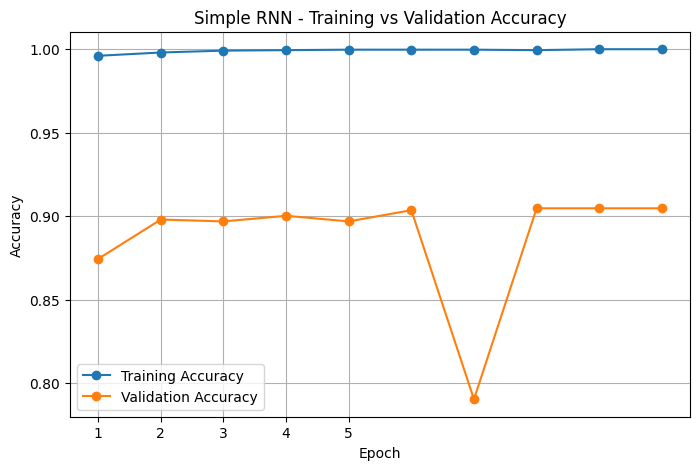

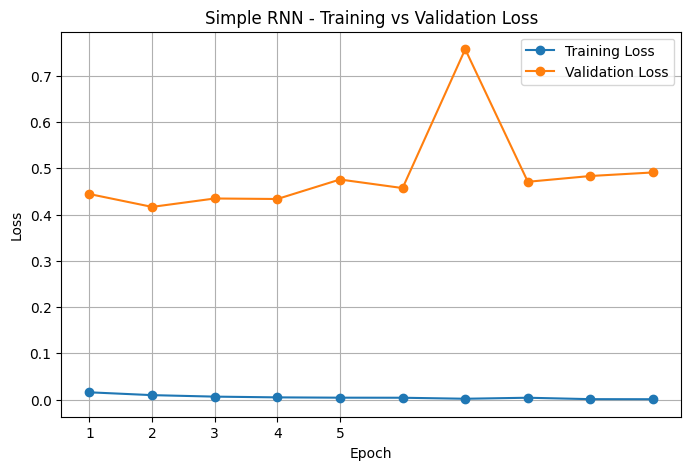

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(rnn_history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(rnn_history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Simple RNN - Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(rnn_history.history["loss"], marker="o", label="Training Loss")
plt.plot(rnn_history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Simple RNN - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(5), range(1, 6))
plt.legend()
plt.grid(True)
plt.show()

**Vanishing Gradient Problem**

In a plain RNN, gradients can become extremely small as they are passed backward through many time steps. As a result, the model struggles to learn long-term relationships between words in long sequences.